# 1. Channel Fingerprint Map Generation

Run this notebook from the repository root after generating the scene with [scene.ipynb](scene.ipynb), or use the included scene files. It writes `results/data/fingerprint.npz` for notebook 02.

The 5.8 GHz path search enables LoS, specular reflection, and refraction (transmission/penetration), with at most five interactions. The final map retains paths with zero or one exterior-wall reflection; these may also penetrate interior obstacles. Diffuse reflection and diffraction are disabled.

Exterior walls are reflection-only (`rho = 0.70`, an amplitude coefficient). Concrete and wood are transmission-only (50 dB/m and 8 dB/m). These material coefficients are frequency-independent. Obstacles use thin vertical interaction planes with thickness applied in the attenuation model; the plots show their full ground footprints. Transmission continues in the incident direction.

`P_REF_DBM = -5` is the transmit power per subcarrier. With 64 equally powered subcarriers, the total is approximately 13.06 dBm. Noise is computed over one subcarrier's bandwidth. See the [README](README.md#propagation-and-custom-material-model) for the geometry and material assumptions.

## 0. Setup

### Imports

In [1]:
import numpy as np
import importlib
import matplotlib.pyplot as plt
import sionna.rt

from matplotlib.patches import Rectangle, Circle

from sionna.rt import (
    load_scene,
    Transmitter,
    Receiver,
    PlanarArray,
    PathSolver,
    InteractionType,
    subcarrier_frequencies,
)

print("Sionna RT version:", sionna.rt.__version__)

Sionna RT version: 2.0.1


### Load `project_config.py`

In [2]:
import project_config

importlib.reload(project_config)

from project_config import (
    ROOM_X,
    ROOM_Y,
    BS_CENTER,
    RX_HEIGHT,
    FREQ_HZ,
    BW_HZ,
    N_SC,
    DF_HZ,
    P_REF_DBM,
    NOISE_SC_DBM,
    GRID_RES,
    N_ROWS,
    N_COLS,
    CELL_X,
    CELL_Y,
    RX_POINTS,
    SCENE_XML,
    DATA_DIR,
    FINGERPRINT_PATH,
    AMR1_START_XY,
    AMR1_GOAL_XY,
    AMR2_START_XY,
    AMR2_GOAL_XY,
    OBSTACLES,
)

print("Scene XML:", SCENE_XML)
print("BS:", BS_CENTER)
print("RX points:", RX_POINTS.shape)

Scene XML: /home/sjyun/git/warehouse-amr-radio-resource-allocation/scene/scene_interaction.xml
BS: [3.  5.  2.7]
RX points: (720, 3)


### Register the custom radio-material plugin

In [3]:
# Required: import-time registration lets load_scene resolve the custom
# `project-radio-material-v1` BSDF declared in scene_interaction.xml.
import project_radio_material

scene = load_scene(
    str(SCENE_XML),
    # Preserve individual geometry objects for path filtering and visualization.
    merge_shapes=False,
)

scene.frequency = FREQ_HZ
scene.bandwidth = BW_HZ

print("Scene loaded successfully")
print("Number of objects:", len(scene.objects))

Registered Mitsuba BSDF plugin: project-radio-material-v1
Scene loaded successfully
Number of objects: 16


## 1. Generate subcarrier frequencies

In [4]:
f = subcarrier_frequencies(
    num_subcarriers=N_SC,
    subcarrier_spacing=DF_HZ,
)

SC_OFFSETS_HZ = np.asarray(
    f.numpy() if hasattr(f, "numpy") else f,
    dtype=float,
)

SC_RF_HZ = FREQ_HZ + SC_OFFSETS_HZ

print("Number of subcarriers:", len(SC_OFFSETS_HZ))
print("Frequency range:", SC_RF_HZ[0], "~", SC_RF_HZ[-1])

Number of subcarriers: 64
Frequency range: 5790000000.0 ~ 5809687500.0


## 2. Configure transmitter and receiver locations

In [5]:
# =========================================================
# Configure the antenna
# =========================================================

scene.tx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V",
)

scene.rx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V",
)


# =========================================================
# Add one transmitter at the BS
# =========================================================

scene.add(
    Transmitter(
        name="BS",
        position=BS_CENTER.tolist(),
    )
)


# =========================================================
# Add one receiver at each of the 720 grid cells
# =========================================================

for i, pos in enumerate(RX_POINTS):
    scene.add(
        Receiver(
            name=f"rx{i:03d}",
            position=pos.tolist(),
        )
    )

print("BS added:", BS_CENTER)
print("Receivers added:", len(RX_POINTS))

BS added: [3.  5.  2.7]
Receivers added: 720


## 3. Search for propagation paths with PathSolver

In [6]:
solver = PathSolver()
paths = solver(
    scene=scene,
    max_depth=5,   # Includes both reflections and penetration
    synthetic_array=True,
    los=True,
    specular_reflection=True,   # Specular reflection
    diffuse_reflection=False,   # Diffuse reflection
    refraction=True,            # Transmission (penetration)
    diffraction=False,
    edge_diffraction=False,
)

print("PathSolver finished")

valid_rt = np.asarray(paths.valid.numpy(),dtype=bool,)
paths_per_receiver = np.sum(valid_rt,axis=-1,)
print("paths found:", int(np.sum(valid_rt)))

PathSolver finished
paths found: 15544


In [7]:
# ---------------------------------------
# Retain paths with zero or one exterior-wall reflection, including penetration
# ---------------------------------------

valid_rt = np.asarray(paths.valid.numpy(), dtype=bool)
interactions_rt = np.asarray(paths.interactions.numpy())

SPECULAR_T = int(InteractionType.SPECULAR)

# Count exterior-wall reflections for each path
# Do not count transmission through interior obstacles (REFRACTION)
n_wall_reflections = np.sum(
    interactions_rt == SPECULAR_T,
    axis=0,
)

# Retain paths with zero or one exterior-wall reflection
# 0: Unreflected paths (unobstructed LoS or interior-obstacle penetration)
# 1: First-order exterior-wall reflection (may include interior transmission)
keep_paths = (
    valid_rt
    & (n_wall_reflections <= 1)
)

filtered_path_count = np.sum(
    keep_paths,
    axis=-1,
)

print(
    "Total paths remaining:",
    int(np.sum(filtered_path_count)),
)

Total paths remaining: 3473


## 4. Compute the CFR (Channel Frequency Response)

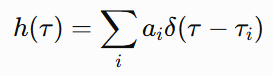

In [8]:
# =========================================================
# Retrieve the per-path CIR computed by Sionna and apply filtering
# =========================================================

a_paths, tau_paths = paths.cir(
    normalize_delays=False,
    num_time_steps=1,
    out_type="numpy",
)

a_paths = np.asarray(a_paths)        # complex path coefficient
tau_paths = np.asarray(tau_paths)    # time delay


# tau_paths and keep_paths both have shape [receiver, transmitter, path]
if tau_paths.shape != keep_paths.shape:
    raise ValueError(
        f"tau and path-mask shapes differ: "
        f"{tau_paths.shape} vs {keep_paths.shape}"
    )


# Expand keep_paths to match the shape of a_paths, then
# set the complex channel coefficients of excluded paths to zero
path_mask = keep_paths[:, None, :, None, :, None]
a_filtered = a_paths * path_mask

In [9]:
# =========================================================
# Compute the 64-subcarrier CFR using the filtered paths (a_filtered)
# =========================================================

# Expand delay to the dimensions used for CFR computation
tau_expanded = tau_paths[:, None, :, None, :, None]

# Delay phase for each path and subcarrier
path_phase = np.exp(-1j* 2.0* np.pi* tau_expanded* SC_OFFSETS_HZ[None, None, None, None, None, :])

# Complex channel contribution of each path to each subcarrier
path_cfr = a_filtered * path_phase

# Sum retained complex path contributions, including interior penetration
H_links = np.sum(path_cfr, axis=4)


# Remove singleton SISO dimensions
H_flat = H_links[:, 0, 0, 0, :]

# Reshape 720 receivers into a 20 × 36 grid
H = H_flat.reshape(N_ROWS,N_COLS,N_SC,)

print("Fingerprint H shape (rows, columns, subcarriers):", H.shape)

Fingerprint H shape (rows, columns, subcarriers): (20, 36, 64)


In [10]:
# =========================================================
# Per-subcarrier and average SNR
# =========================================================

# P_REF_DBM is transmit power per subcarrier; convert it to watts.
p_ref_w = 10.0 ** ((P_REF_DBM - 30.0) / 10.0)
# Noise power is integrated over DF_HZ, the bandwidth of one subcarrier.
noise_sc_w = 10.0 ** ((NOISE_SC_DBM - 30.0) / 10.0)

# SNR for each subcarrier
snr_sc_linear = (
    p_ref_w
    * np.abs(H)**2
    / noise_sc_w
)

# Average across 64 subcarriers
snr_linear = np.mean(
    snr_sc_linear,
    axis=2,
)

# Convert SNR to dB
snr_db = 10.0 * np.log10(
    np.maximum(snr_linear, 1e-30)
)

print("Per-subcarrier SNR shape:", snr_sc_linear.shape)
print("Average SNR map shape   :", snr_db.shape)
print("SNR range:", snr_db.min(), "~", snr_db.max(), "dB")


# =========================================================
# Save the fingerprint
# =========================================================

DATA_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    FINGERPRINT_PATH,
    H=H,
    snr_db=snr_db,
    snr_sc_linear=snr_sc_linear,
    cell_x=CELL_X,
    cell_y=CELL_Y,
    sc_rf_hz=SC_RF_HZ,
    grid_res=GRID_RES,
    room_x=ROOM_X,
    room_y=ROOM_Y,
)

print("Saved:", FINGERPRINT_PATH)

Per-subcarrier SNR shape: (20, 36, 64)
Average SNR map shape   : (20, 36)
SNR range: -15.031700729078551 ~ 53.278071960103034 dB
Saved: /home/sjyun/git/warehouse-amr-radio-resource-allocation/results/data/fingerprint.npz


## 5. Verify and analyze the SNR map

In [11]:
# =========================================================
# Inspect SNR at reference locations
# =========================================================

# Function that finds the nearest grid cell to (x, y)
def cell_of(x, y):
    c = int(np.argmin(np.abs(CELL_X - x)))
    r = int(np.argmin(np.abs(CELL_Y - y)))
    return r, c

# Illustrative expectations for the default scene, not measured validation data.
for (x, y), tgt in [((3.0, 3.0), "≈ 50 dB"), ((13.0, 5.0), "≲ 25 dB")]:
    r, c = cell_of(x, y)
    print(f"({x:4.1f},{y:4.1f}) -> cell({CELL_X[c]:5.2f},{CELL_Y[r]:5.2f})  "
          f"SNR = {snr_db[r, c]:6.2f} dB   (target {tgt})")

( 3.0, 3.0) -> cell( 2.75, 2.75)  SNR =  48.55 dB   (target ≈ 50 dB)
(13.0, 5.0) -> cell(12.75, 4.75)  SNR =  15.75 dB   (target ≲ 25 dB)


In [12]:
# =========================================================
# Maximum and minimum values in the full SNR map
# =========================================================

# Find the cell with the largest value in snr_db
r_hi, c_hi = np.unravel_index(np.argmax(snr_db), snr_db.shape)

# Find the cell with the smallest value in snr_db
r_lo, c_lo = np.unravel_index(np.argmin(snr_db), snr_db.shape)

print(f"brightest ({CELL_X[c_hi]:5.2f},{CELL_Y[r_hi]:5.2f})       : {snr_db[r_hi,c_hi]:6.2f} dB")
print(f"darkest   ({CELL_X[c_lo]:5.2f},{CELL_Y[r_lo]:5.2f})       : {snr_db[r_lo,c_lo]:6.2f} dB")
print(f"contrast (maximum SNR - minimum SNR): {snr_db[r_hi,c_hi] - snr_db[r_lo,c_lo]:6.2f} dB")

brightest ( 2.75, 3.75)       :  53.28 dB
darkest   (13.75, 4.75)       : -15.03 dB
contrast (maximum SNR - minimum SNR):  68.31 dB


In [13]:
# =========================================================
# Inspect SNR along an illustrative AMR 1 route
# =========================================================

# Match notebook 02: interpolate linear SNR, then convert the mean to dB.
def snr_bilinear(x, y):
    fx = (np.asarray(x, dtype=float) - CELL_X[0]) / GRID_RES
    fy = (np.asarray(y, dtype=float) - CELL_Y[0]) / GRID_RES
    i = np.clip(np.floor(fx).astype(int), 0, N_COLS - 2)
    j = np.clip(np.floor(fy).astype(int), 0, N_ROWS - 2)
    a = np.clip(fx - i, 0.0, 1.0)
    b = np.clip(fy - j, 0.0, 1.0)
    # snr_linear is the mean of the per-subcarrier linear SNR map.
    # Averaging and bilinear interpolation commute in the linear domain.
    mean_linear = (
        (1-a)*(1-b)*snr_linear[j, i] + a*(1-b)*snr_linear[j, i+1]
        + (1-a)*b*snr_linear[j+1, i] + a*b*snr_linear[j+1, i+1]
    )
    return 10.0 * np.log10(np.maximum(mean_linear, 1e-30))

# Illustrative waypoints; collision and clearance checks belong to notebook 02.
wp  = np.array([[1., 2.], [9., 5.25], [17., 8.]])

# Calculate each segment length and the total path length
seg = np.linalg.norm(np.diff(wp, axis=0), axis=1)
L   = seg.sum()

print(f"Approximate AMR 1 path length: {L:.2f} m")
for s in np.linspace(0, L, 6):
    if s <= seg[0]:
        p = wp[0] + (s / seg[0]) * (wp[1] - wp[0])
    else:
        p = wp[1] + ((s - seg[0]) / seg[1]) * (wp[2] - wp[1])
    print(f"  s={s:5.2f} m  ({p[0]:5.2f},{p[1]:5.2f})  SNR = {snr_bilinear(*p):6.2f} dB")

Approximate AMR 1 path length: 17.09 m
  s= 0.00 m  ( 1.00, 2.00)  SNR =  46.40 dB
  s= 3.42 m  ( 4.17, 3.29)  SNR =  49.46 dB
  s= 6.84 m  ( 7.33, 4.57)  SNR =  43.57 dB
  s=10.26 m  (10.53, 5.78)  SNR =  18.05 dB
  s=13.68 m  (13.77, 6.89)  SNR =  22.17 dB
  s=17.09 m  (17.00, 8.00)  SNR =  21.48 dB


## 6. Generate the heatmap

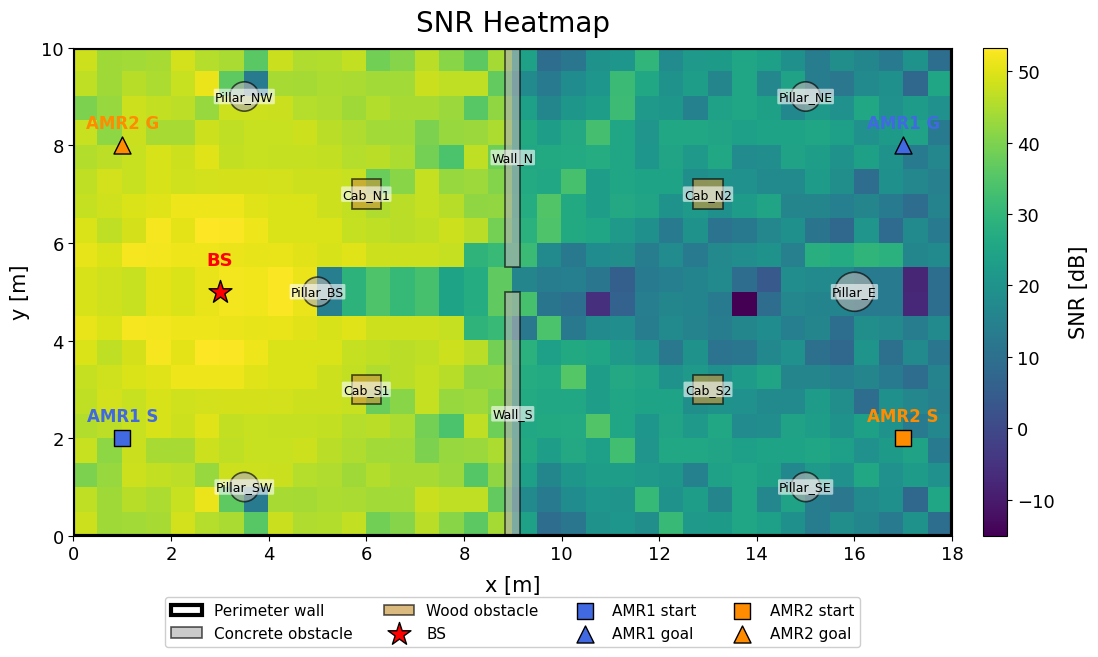

In [14]:
# AMR start and goal locations
AMR1_START = tuple(AMR1_START_XY)
AMR1_GOAL = tuple(AMR1_GOAL_XY)
AMR2_START = tuple(AMR2_START_XY)
AMR2_GOAL = tuple(AMR2_GOAL_XY)

fig, ax = plt.subplots(figsize=(12, 6.5))

# ---------------------------------------
# 1. SNR heat map
# ---------------------------------------
im = ax.imshow(
    snr_db, origin="lower",
    extent=[CELL_X[0] - GRID_RES/2, CELL_X[-1] + GRID_RES/2,
            CELL_Y[0] - GRID_RES/2, CELL_Y[-1] + GRID_RES/2],
    cmap="viridis", aspect="equal", zorder=0,
)

# ---------------------------------------
# 2. Exterior walls
# ---------------------------------------
ax.add_patch(Rectangle((0, 0), ROOM_X, ROOM_Y, fill=False, edgecolor="black",
                       linewidth=3, zorder=4, label="Perimeter wall"))

# ---------------------------------------
# 3. Interior obstacles
# ---------------------------------------
concrete_label_used = False
wood_label_used = False

for ob in OBSTACLES:
    if ob["material"] == "wood":
        color = "#c8963c"
        label = None if wood_label_used else "Wood obstacle"
        wood_label_used = True
    else:
        color = "#b0b0b0"
        label = None if concrete_label_used else "Concrete obstacle"
        concrete_label_used = True

    # Central walls or cabinets
    if ob["kind"] == "box":
        dx, dy, _ = ob["size"]
        x, y = ob["center"]
        ax.add_patch(Rectangle((x - dx/2, y - dy/2), dx, dy, facecolor=color,
                               edgecolor="black", linewidth=1.2, alpha=0.65,
                               zorder=3, label=label))
    # Cylinders
    else:
        x, y = ob["center"]
        ax.add_patch(Circle((x, y), ob["radius"], facecolor=color,
                            edgecolor="black", linewidth=1.2, alpha=0.65,
                            zorder=3, label=label))

    # Obstacle name
    ax.annotate(ob["name"], ob["center"], fontsize=9, color="black",
                ha="center", va="center", zorder=5,
                bbox=dict(boxstyle="round,pad=0.1", facecolor="white",
                          edgecolor="none", alpha=0.6))

# ---------------------------------------
# 4. BS location
# ---------------------------------------
ax.scatter(BS_CENTER[0], BS_CENTER[1], marker="*", s=300, color="red",
           edgecolor="black", linewidth=1.0, zorder=7, label="BS")
ax.annotate("BS", BS_CENTER[:2], xytext=(3.0, 5.55), fontsize=13,
            fontweight="bold", color="red", ha="center", zorder=7)

# ---------------------------------------
# 5. AMR 1 start and goal locations
# ---------------------------------------
ax.scatter(*AMR1_START, marker="s", s=120, color="royalblue",
           edgecolor="black", zorder=7, label="AMR1 start")
ax.scatter(*AMR1_GOAL, marker="^", s=150, color="royalblue",
           edgecolor="black", zorder=7, label="AMR1 goal")
ax.annotate("AMR1 S", AMR1_START, xytext=(1.0, 2.35), ha="center", fontsize=12,
            color="royalblue", fontweight="bold", zorder=7)
ax.annotate("AMR1 G", AMR1_GOAL, xytext=(17.0, 8.35), ha="center", fontsize=12,
            color="royalblue", fontweight="bold", zorder=7)

# ---------------------------------------
# 6. AMR 2 start and goal locations
# ---------------------------------------
ax.scatter(*AMR2_START, marker="s", s=120, color="darkorange",
           edgecolor="black", zorder=7, label="AMR2 start")
ax.scatter(*AMR2_GOAL, marker="^", s=150, color="darkorange",
           edgecolor="black", zorder=7, label="AMR2 goal")
ax.annotate("AMR2 S", AMR2_START, xytext=(17.0, 2.35), ha="center", fontsize=12,
            color="darkorange", fontweight="bold", zorder=7)
ax.annotate("AMR2 G", AMR2_GOAL, xytext=(1.0, 8.35), ha="center", fontsize=12,
            color="darkorange", fontweight="bold", zorder=7)

# ---------------------------------------
# 7. Plot configuration
# ---------------------------------------
ax.set_xlim(0, ROOM_X)
ax.set_ylim(0, ROOM_Y)

# Axis labels
ax.set_xlabel(
    "x [m]",
    fontsize=15,
    labelpad=8,
)

ax.set_ylabel(
    "y [m]",
    fontsize=15,
    labelpad=8,
)

# Plot title
ax.set_title(
    "SNR Heatmap",
    fontsize=20,
    pad=12,
)

# Axis tick values
ax.tick_params(
    axis="both",
    labelsize=13,
)

ax.set_aspect("equal")


# Colorbar
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.03,
)

cbar.set_label(
    "SNR [dB]",
    fontsize=15,
    labelpad=10,
)

cbar.ax.tick_params(
    labelsize=13,
)


# Legend
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.11),
    ncol=4,
    fontsize=11,        # Previously 8
    framealpha=0.95,
)

fig.tight_layout()
plt.show()

## 7. Calculate paths with two AMRs as receivers

In [15]:
# ---------------------------
# Solve paths separately with the AMR starting locations as receivers
# (Keep the 720-grid-cell scene unchanged and instantiate a separate scene.)
# ---------------------------
AMR1_START = tuple(AMR1_START_XY)
AMR2_START = tuple(AMR2_START_XY)

AMR_POINTS = {
    "AMR1": (AMR1_START[0], AMR1_START[1], RX_HEIGHT),
    "AMR2": (AMR2_START[0], AMR2_START[1], RX_HEIGHT),
}

scene_amr = load_scene(str(SCENE_XML), merge_shapes=False)
scene_amr.frequency = FREQ_HZ
scene_amr.bandwidth = BW_HZ

scene_amr.tx_array = PlanarArray(
    num_rows=1, num_cols=1,
    vertical_spacing=0.5, horizontal_spacing=0.5,
    pattern="iso", polarization="V",
)
scene_amr.rx_array = PlanarArray(
    num_rows=1, num_cols=1,
    vertical_spacing=0.5, horizontal_spacing=0.5,
    pattern="iso", polarization="V",
)

scene_amr.add(Transmitter(name="BS", position=BS_CENTER.tolist()))

amr_names = list(AMR_POINTS.keys())
for name, pos in AMR_POINTS.items():
    scene_amr.add(Receiver(name=name, position=[float(v) for v in pos]))

solver_amr = PathSolver()
paths_amr = solver_amr(
    scene=scene_amr,
    max_depth=5,
    synthetic_array=True,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    refraction=True,
    diffraction=False,
    edge_diffraction=False,
)

print("PathSolver finished")

# With synthetic_array=True, geometry arrays have no antenna axes.
valid_amr = np.asarray(paths_amr.valid.numpy())               # [rx, tx, path]
vertices_amr = np.asarray(paths_amr.vertices.numpy())         # [depth, rx, tx, path, xyz]
interactions_amr = np.asarray(paths_amr.interactions.numpy()) # [depth, rx, tx, path]
sources_amr = np.asarray(paths_amr.sources.numpy()).T           # BS location, shape (num_tx, 3)
targets_amr = np.asarray(paths_amr.targets.numpy()).T           # AMR locations, shape (num_rx, 3)

for i, name in enumerate(amr_names):
    n_valid = int(valid_amr[i, 0, :].sum())   # Receiver i, the single BS, all paths
    print(f"{name}: {n_valid} valid paths")

PathSolver finished
AMR1: 27 valid paths
AMR2: 24 valid paths


In [16]:
# ---------------------------------------
# Filter AMR 1 and AMR 2 paths
# Retain only paths with zero or one exterior-wall reflection
# ---------------------------------------

valid_amr_rt = np.asarray(
    paths_amr.valid.numpy(),
    dtype=bool,
)

interactions_amr_rt = np.asarray(
    paths_amr.interactions.numpy()
)

SPECULAR_T = int(InteractionType.SPECULAR)

print("valid_amr_rt shape       :", valid_amr_rt.shape)
print("interactions_amr_rt shape:", interactions_amr_rt.shape)


# Count exterior-wall reflections for each AMR path
# Do not count transmission through interior obstacles (REFRACTION)
n_wall_reflections_amr = np.sum(
    interactions_amr_rt == SPECULAR_T,
    axis=0,
)

# Remove paths with two or more exterior-wall reflections
keep_amr_paths = (
    valid_amr_rt
    & (n_wall_reflections_amr < 2)
)

# Path counts before and after filtering for each AMR
original_amr_paths = np.sum(
    valid_amr_rt,
    axis=-1,
).reshape(-1)

filtered_amr_paths = np.sum(
    keep_amr_paths,
    axis=-1,
).reshape(-1)


amr_names = ["AMR1", "AMR2"]

print("\n[AMR path filtering results]")

for i, name in enumerate(amr_names):
    removed = (
        original_amr_paths[i]
        - filtered_amr_paths[i]
    )

    print(
        f"{name}: "
        f"Before filtering: {original_amr_paths[i]} → "
        f"After filtering: {filtered_amr_paths[i]} "
    )

valid_amr_rt shape       : (2, 1, 27)
interactions_amr_rt shape: (5, 2, 1, 27)

[AMR path filtering results]
AMR1: Before filtering: 27 → After filtering: 5 
AMR2: Before filtering: 24 → After filtering: 5 


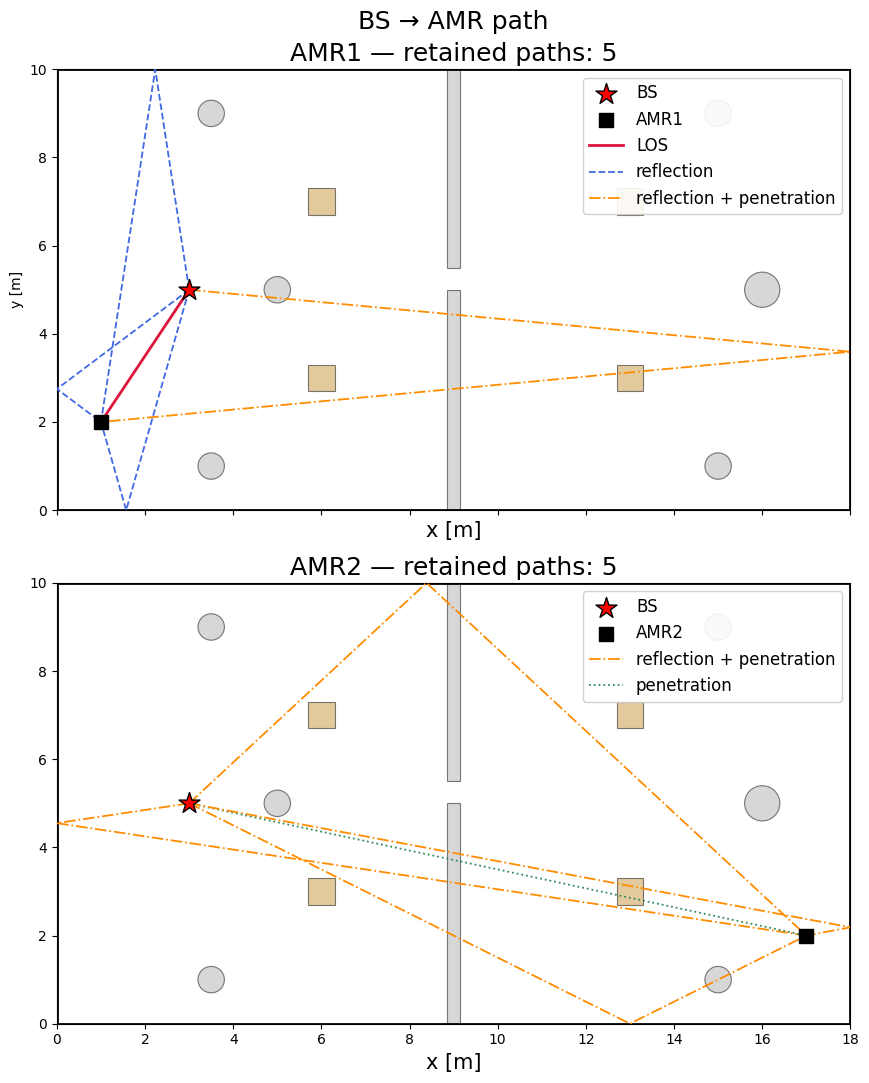

In [17]:
# ---------------------------------------
# Visualize paths found for each AMR as lines over the warehouse layout
# ---------------------------------------
plt.rcParams["font.family"] = "DejaVu Sans"      # Cross-platform font with broad glyph support
plt.rcParams['axes.unicode_minus'] = False       # Prevent minus-sign rendering issues

NONE_T = int(InteractionType.NONE)
SPECULAR_T = int(InteractionType.SPECULAR)
REFRACTION_T = int(InteractionType.REFRACTION)

def path_xy_chain(r_idx, p_idx):
    """Return (x, y) vertices for receiver r_idx and path p_idx in BS-to-AMR order."""
    chain = [sources_amr[0, :2]]  # BS (only one transmitter, so index 0)
    for d in range(vertices_amr.shape[0]):  # max_depth
        if interactions_amr[d, r_idx, 0, p_idx] == NONE_T:
            break  # All subsequent slots are unused (paths fill slots from the front)
        chain.append(vertices_amr[d, r_idx, 0, p_idx, :2])
    chain.append(targets_amr[r_idx, :2])
    return np.array(chain)

def classify_path(r_idx, p_idx):
    types = set()
    for d in range(interactions_amr.shape[0]):
        t = int(interactions_amr[d, r_idx, 0, p_idx])
        if t != NONE_T:
            types.add(t)
    if not types:
        return "LOS"
    if types == {SPECULAR_T}:
        return "reflect"
    if types == {REFRACTION_T}:
        return "transmit"
    return "mixed"

STYLE = {
    "LOS":      dict(color="crimson",    linestyle="-",  linewidth=2.0, label="LOS"),
    "reflect":  dict(color="royalblue",  linestyle="--", linewidth=1.3, label="reflection"),
    "transmit": dict(color="seagreen",   linestyle=":",  linewidth=1.3, label="penetration"),
    "mixed":    dict(color="darkorange", linestyle="-.", linewidth=1.3, label="reflection + penetration"),
}

fig, axes = plt.subplots(len(amr_names), figsize=(11, 11), sharex=True, sharey=True)
if len(amr_names) == 1:
    axes = [axes]

for ax, name in zip(axes, amr_names):
    r_idx = amr_names.index(name)

    ax.add_patch(Rectangle((0, 0), ROOM_X, ROOM_Y, fill=False,
                            edgecolor="black", linewidth=2, zorder=4))
    for ob in OBSTACLES:
        color = "#c8963c" if ob["material"] == "wood" else "#b0b0b0"
        if ob["kind"] == "box":
            dx, dy, _ = ob["size"]
            x, y = ob["center"]
            ax.add_patch(Rectangle((x - dx/2, y - dy/2), dx, dy,
                                    facecolor=color, edgecolor="black",
                                    linewidth=0.8, alpha=0.5, zorder=2))
        else:
            x, y = ob["center"]
            ax.add_patch(Circle((x, y), ob["radius"], facecolor=color,
                                 edgecolor="black", linewidth=0.8, alpha=0.5, zorder=2))

    ax.scatter(*BS_CENTER[:2], marker="*", s=250, color="red",
               edgecolor="black", zorder=6, label="BS")
    ax.scatter(*targets_amr[r_idx, :2], marker="s", s=100, color="black",
               zorder=6, label=name)

    used_labels = set()
    n_valid = int(keep_amr_paths[r_idx, 0, :].sum())

    for p_idx in range(keep_amr_paths.shape[-1]):
        if not keep_amr_paths[r_idx, 0, p_idx]:
            continue

        kind = classify_path(r_idx, p_idx)
        chain = path_xy_chain(r_idx, p_idx)
        style = dict(STYLE[kind])
        if kind in used_labels:
            style["label"] = None
        used_labels.add(kind)
        ax.plot(chain[:, 0], chain[:, 1], zorder=5, **style)

    ax.set_title(f"{name} — retained paths: {n_valid}", fontsize=18,)
    ax.set_xlim(0, ROOM_X)
    ax.set_ylim(0, ROOM_Y)
    ax.set_aspect("equal")
    ax.set_xlabel("x [m]", fontsize=15)
    ax.legend(loc="upper right", fontsize=12, framealpha=0.9)

axes[0].set_ylabel("y [m]")
fig.suptitle("BS → AMR path", fontsize=18)
fig.tight_layout()
plt.show()